# Capítulo 2 — PD a 12 meses con cortes mensuales

**Objetivo.** Construir la PD a 12 meses de una cartera hipotecaria: un scorecard que **ordena** a los deudores por riesgo y una **calibración** que convierte ese orden en una probabilidad. En NIIF 9 esta PD es el insumo de Stage 1 y el punto de partida de la PD de vida del capítulo 3.

**Cómo se arma en un banco.** El data warehouse guarda la foto de **cierre de mes** de cada cuenta —en Perú, el Reporte Crediticio de Deudores a la SBS es mensual—. Cada cierre es un **corte**: se toman las variables de la cuenta en esa fecha y se observa si cae en default en los 12 meses siguientes.

**La base.** Cartera hipotecaria **sintética**: cada crédito se simula mes a mes desde su originación. Una fila por cuenta vigente en cada cierre de mes, de enero 2003 a diciembre 2018. Formato parquet; necesita `pyarrow` y `statsmodels`.

**Las dos ventanas**, la regla que atraviesa todo el notebook:

```
     ventana de observación              corte               ventana de desempeño
|--------------------------------|   report_date   |------------------------------|
   las VARIABLES viven acá                            el EVENTO vive acá
   (foto al corte + historia)                         (12 meses hacia adelante)
```

Una variable que mire hacia la derecha del corte es **fuga de información**: en producción no existe.

**El recorrido:** carga → cortes y solape → ciclo → partición → WOE e IV → logística → puntaje y calibración → validación → estabilidad → machine learning → backtest.

In [22]:
#pip install pandas numpy matplotlib scikit-learn statsmodels pyarrow jupyterlab

## Librerías

In [23]:
import numpy as np, pandas as pd, os, warnings            # cálculo, tablas y utilidades del sistema
import matplotlib.pyplot as plt                           # gráficos
plt.style.use('seaborn-v0_8')                             # estilo visual de los gráficos
from sklearn.metrics import roc_auc_score, roc_curve      # AUC y curva ROC: base del Gini y del KS
from sklearn.ensemble import RandomForestClassifier       # modelo de contraste de machine learning
from sklearn.tree import DecisionTreeClassifier           # árbol de una variable: define los cortes del WOE
from sklearn.model_selection import train_test_split      # partición aleatoria de las CUENTAS
import statsmodels.api as sm                              # regresión logística con errores estándar y p-valores
warnings.filterwarnings('ignore', category=FutureWarning) # oculta avisos de versiones de pandas
os.makedirs('figs_m', exist_ok=True)                      # carpeta donde se guardan los gráficos
pd.set_option('display.max_columns', None)                # muestra todas las columnas al imprimir tablas

## Carga y variable objetivo

La base trae **tres disparadores** de default, medidos en los 12 meses siguientes a cada corte (Bellini §2.2.1, pp. 33–34):

- `arrears_event`: la cuenta llega a 3 cuotas impagas (el ancla de 90 días de Basilea).
- `bankrupt_event`: quiebra del deudor.
- `term_expiry_event`: el crédito vence con saldo sin pagar.

La variable objetivo `default_event` vale 1 si ocurre **cualquiera** de los tres: es un "o" lógico, que en código es el máximo entre las tres columnas.

Los dos `assert` verifican la coherencia de la base: una cuenta vigente nunca tiene 3 cuotas impagas —ese día defaultea y sale de la muestra—, y en una ventana de 12 meses no caben más de 12 meses de mora.

In [24]:
df = pd.read_parquet('chap2oneypd_mensual.parquet')                      # base de cortes mensuales
macro = pd.read_csv('macro.csv', parse_dates=['report_date'])            # macro trimestral, fechada al cierre de cada trimestre

# default = cualquiera de los tres disparadores: el máximo de tres columnas 0/1 es su "o" lógico
df['default_event'] = df[['arrears_event', 'bankrupt_event', 'term_expiry_event']].max(axis=1).astype(np.int8)

# coherencia: una cuenta vigente tiene menos de 3 cuotas impagas, y la mora máxima de 12 meses no pasa de 12
assert (df.arrears_months < 3).all() and (df.max_arrears_12m <= 12).all()

print(f'filas {len(df):,} | cuentas {df.id.nunique():,} | cierres de mes {df.report_date.nunique()} '
      f'({df.report_date.min():%Y-%m} a {df.report_date.max():%Y-%m})')
# la media de una variable 0/1 es la proporción de unos: aquí, la tasa de default (DR)
print(f'DR global {df.default_event.mean()*100:.2f}% | duplicados (id, corte): '
      f'{df.duplicated(["id", "report_date"]).sum()} | memoria {df.memory_usage(deep=True).sum()/1e6:.0f} MB')

filas 2,302,232 | cuentas 26,100 | cierres de mes 192 (2003-01 a 2018-12)
DR global 2.39% | duplicados (id, corte): 0 | memoria 226 MB


## Los cortes

Cada fecha distinta de `report_date` es un cierre de mes. La lista confirma que no falta ninguno y dónde empieza y termina la base.

In [25]:
df_1 = df['report_date'].unique().tolist()   # fechas de corte distintas
df_1.sort()                                  # en orden cronológico
df_1

[Timestamp('2003-01-31 00:00:00'),
 Timestamp('2003-02-28 00:00:00'),
 Timestamp('2003-03-31 00:00:00'),
 Timestamp('2003-04-30 00:00:00'),
 Timestamp('2003-05-31 00:00:00'),
 Timestamp('2003-06-30 00:00:00'),
 Timestamp('2003-07-31 00:00:00'),
 Timestamp('2003-08-31 00:00:00'),
 Timestamp('2003-09-30 00:00:00'),
 Timestamp('2003-10-31 00:00:00'),
 Timestamp('2003-11-30 00:00:00'),
 Timestamp('2003-12-31 00:00:00'),
 Timestamp('2004-01-31 00:00:00'),
 Timestamp('2004-02-29 00:00:00'),
 Timestamp('2004-03-31 00:00:00'),
 Timestamp('2004-04-30 00:00:00'),
 Timestamp('2004-05-31 00:00:00'),
 Timestamp('2004-06-30 00:00:00'),
 Timestamp('2004-07-31 00:00:00'),
 Timestamp('2004-08-31 00:00:00'),
 Timestamp('2004-09-30 00:00:00'),
 Timestamp('2004-10-31 00:00:00'),
 Timestamp('2004-11-30 00:00:00'),
 Timestamp('2004-12-31 00:00:00'),
 Timestamp('2005-01-31 00:00:00'),
 Timestamp('2005-02-28 00:00:00'),
 Timestamp('2005-03-31 00:00:00'),
 Timestamp('2005-04-30 00:00:00'),
 Timestamp('2005-05-

## Ventanas solapadas: por qué la partición necesita cuidado

La ventana de un cierre son los 12 meses siguientes. Cierres consecutivos **comparten 11 de esos 12 meses**. Una cuenta que defaultea en junio 2009 tiene ese evento en la ventana de todos los cierres de junio 2008 a mayo 2009: **12 filas con `default_event = 1`, de la misma cuenta, por el mismo evento.**

Esto no sesga los coeficientes ni el Gini. Lo que sí obliga es a cuidar la partición: si algunas de esas 12 filas quedaran en entrenamiento y otras en validación, el modelo se estaría validando con un evento que ya vio. Por eso, más adelante, se parte **por cuenta** y se deja un **embargo** en el tiempo.

`rep` cuenta cuántas filas con evento tiene cada cuenta: la mayoría tiene 12.

In [26]:
ev = df[df.default_event == 1]      # solo las filas cuyo evento cae en su ventana
rep = ev.groupby('id').size()       # cuántas de esas filas tiene cada cuenta

In [27]:
rep = ev.groupby('id').size()


In [28]:
print(f'filas con evento: {len(ev):,} | cuentas distintas con evento: {rep.size:,}')
print(f'cada cuenta que defaultea aparece con evento en {rep.mean():.1f} filas en promedio (máximo 12)')
# distribución: cuántas cuentas aparecen 1 vez, 2 veces, ..., 12 veces
print(f'distribución: {rep.value_counts().sort_index().head(12).to_dict()}')

filas con evento: 54,972 | cuentas distintas con evento: 4,552
cada cuenta que defaultea aparece con evento en 12.1 filas en promedio (máximo 12)
distribución: {1: 36, 2: 36, 3: 50, 4: 76, 5: 59, 6: 74, 7: 74, 8: 71, 9: 63, 10: 63, 11: 58, 12: 3476}


## La tasa de default sigue al ciclo

**Qué se mide.** Para cada cierre, la DR es la proporción de cuentas vigentes que defaultea en los 12 meses siguientes. Se compara con la macro **de esos mismos 12 meses**: la economía que vivieron las cuentas mientras defaulteaban.

**El problema del alineamiento.** La ventana del cierre de marzo 2008 va de abril 2008 a marzo 2009: cruza dos años. Hay que calcular la macro mes a mes y promediarla sobre la ventana de cada cierre.

**Trimestral a mensual.** La macro viene fechada al **fin** de cada trimestre y describe lo ocurrido durante ese trimestre. Cada mes toma el valor de su trimestre usando la clave `to_period('Q')`. El atajo `resample().ffill()` está **mal** para datos fechados a fin de período: propaga el valor hacia adelante y le da a abril y mayo el dato del trimestre anterior.

**Advertencia.** Mirar la macro de la ventana es válido para **medir** la relación sobre la historia. Usarla como variable del modelo sería fuga: al cierre nadie conoce la macro de los 12 meses siguientes. En producción se reemplaza por escenarios proyectados.

In [29]:
# cada trimestre como índice: 2008-03-31 -> 2008Q1
mq = macro.assign(q=macro.report_date.dt.to_period('Q')).set_index('q')[['gdp_growth', 'uer']]
# todos los fines de mes cubiertos por la macro (se retrocede 2 meses para incluir ene y feb del primer trimestre)
meses = pd.date_range(macro.report_date.min() - pd.offsets.MonthEnd(2),
                      macro.report_date.max(), freq='ME')
# cada mes toma el valor de SU trimestre: se busca por la clave del trimestre, no se rellena hacia adelante
mm = mq.reindex(meses.to_period('Q')).set_axis(meses)

In [30]:
mm[::-1].rolling(12).mean()


,gdp_growth,uer
2019-12-31,NaN,NaN
2019-11-30,NaN,NaN
2019-10-31,NaN,NaN
2019-09-30,NaN,NaN
2019-08-31,NaN,NaN
...,...,...
1983-05-31,0.722117,5.493533
1983-04-30,0.747525,5.493375
1983-03-31,0.825050,5.495733
1983-02-28,0.902575,5.498092


In [31]:
mm[::-1].rolling(12).mean().head(14)

,gdp_growth,uer
2019-12-31,NaN,NaN
2019-11-30,NaN,NaN
2019-10-31,NaN,NaN
2019-09-30,NaN,NaN
2019-08-31,NaN,NaN
2019-07-31,NaN,NaN
2019-06-30,NaN,NaN
2019-05-31,NaN,NaN
2019-04-30,NaN,NaN
2019-03-31,NaN,NaN


In [32]:
# inspección: promedio de los 12 meses SIGUIENTES a cada fecha.
# rolling() solo mira hacia atrás; invertir la serie, promediar y volver a invertir lo hace mirar hacia adelante.
# shift(-1): la ventana empieza en t+1, no en t.
# Los últimos 12 meses salen vacíos: no hay futuro que promediar. Por eso el último corte usable es dic-2018.
mm[::-1].rolling(12).mean()[::-1].shift(-1).tail(15)

,gdp_growth,uer
2018-10-31,0.701967,6.375225
2018-11-30,0.704108,6.345025
2018-12-31,0.706250,6.314825
2019-01-31,NaN,NaN
2019-02-28,NaN,NaN
2019-03-31,NaN,NaN
2019-04-30,NaN,NaN
2019-05-31,NaN,NaN
2019-06-30,NaN,NaN
2019-07-31,NaN,NaN


Calcula, para cada cierre, el promedio de PBI y desempleo en los 12 meses siguientes (la ventana de desempeño de ese cierre). mm es la macro ya llevada a mensual. Invertir-rolling-invertir hace que el promedio mire hacia adelante en vez de hacia atrás, y shift(-1) corre el resultado una fila para que quede alineado con el mes en que empieza esa ventana (t+1, no t).

192 cierres | corr(DR, PBI ventana) -0.63 | corr(DR, desempleo ventana) +0.93


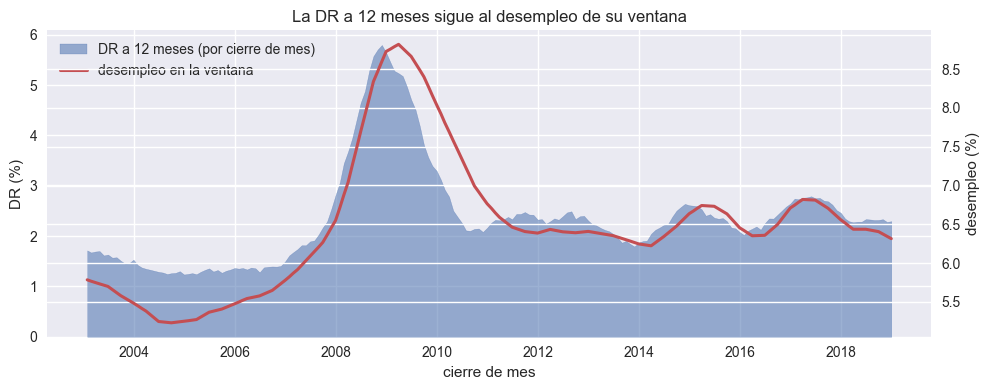

In [33]:
ventana = mm[::-1].rolling(12).mean()[::-1].shift(-1)       # macro promedio de la ventana de cada cierre

dr = df.groupby('report_date').agg(n=('id', 'size'), dr=('default_event', 'mean'))   # DR por cierre
# se une por fecha; el sufijo _w recuerda que es la macro de la VENTANA, no la del cierre
t = dr.join(ventana.rename(columns={'gdp_growth': 'gdp_w', 'uer': 'uer_w'})).dropna()
print(f'{len(t)} cierres | corr(DR, PBI ventana) {t.dr.corr(t.gdp_w):+.2f} | '
      f'corr(DR, desempleo ventana) {t.dr.corr(t.uer_w):+.2f}')

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(t.index, t.dr*100, color='#4c72b0', alpha=.55, label='DR a 12 meses (por cierre de mes)')
ax.set_ylim(0, None)                                          # la DR arranca en cero: es una magnitud
ax2 = ax.twinx()                                              # segundo eje vertical: escalas distintas
ax2.plot(t.index, t.uer_w, c='#c44e52', lw=2.2, label='desempleo en la ventana')
ax.set_ylabel('DR (%)'); ax2.set_ylabel('desempleo (%)'); ax.set_xlabel('cierre de mes')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1+h2, l1+l2, loc='upper left')                     # una sola leyenda con las dos series
ax.set_title('La DR a 12 meses sigue al desempleo de su ventana')
plt.tight_layout(); plt.savefig('figs_m/dr_ciclo_mensual.png', dpi=110); plt.show()

## ¿Cuánto ciclo traen ya las variables del scorecard?

El scorecard **ordena**; la calibración fija el **nivel de hoy**; y en el capítulo 3 una *link function* mueve ese nivel hacia el futuro con escenarios macro. Son tres capas, y la macro se aplica **encima**, no dentro del scorecard.

Entonces, ¿para qué mirar si las variables se mueven con la economía? Por dos razones muy concretas, y las dos aparecen recién al aplicar el desplazamiento macro del capítulo 3:

- **Para no contar el ciclo dos veces.** Si el buró cae y la utilización sube en la crisis, la PD del scorecard ya sube sola. Multiplicarla después por el factor completo de la link function sumaría el mismo efecto dos veces.
- **Para saber si el punto de partida está anclado al presente.** El desplazamiento macro es multiplicativo: si la PD de partida quedó anclada al promedio del ciclo en vez de a las condiciones del corte, el error se arrastra.

**No todas las variables se mueven por la misma razón.** Hay que distinguir tres casos:

- **Cíclicas de verdad**: el valor cambia para la misma cuenta. El buró y la utilización de tarjeta responden a la economía; el LTV, a los precios de vivienda.
- **De envejecimiento**: meses en libros y plazo remanente se mueven 36 meses en 36 meses, con crisis o sin ella.
- **Fijas al origen**: ingreso, DTI, antigüedad laboral. Su media de cartera puede moverse, pero solo porque cambia **quién sigue vigente**.

La segunda celda separa las dos cosas: compara el cambio de la media de la cartera entre un corte de auge y uno de crisis, contra el cambio medido **solo en las cuentas presentes en ambos cortes**. Si una variable cambia en la cartera pero no en las mismas cuentas, lo que se movió fue la composición, no la variable.

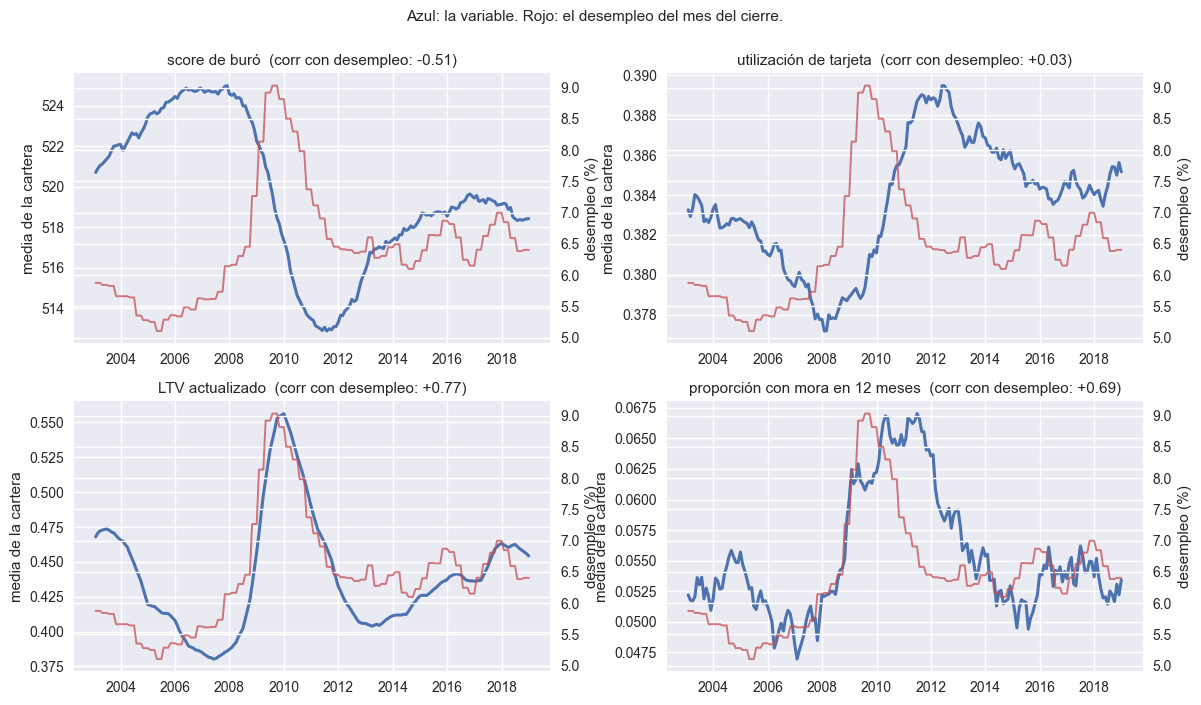

cuentas en dic-2006: 11,989 | en dic-2009: 12,136 | en ambos cortes: 9,632

                 media 2006  media 2009  cambio de la cartera  cambio en las mismas cuentas
bureau_score        524.809     517.335                -7.475                       -12.044
cc_util               0.379       0.381                 0.002                         0.004
ltv_utd               0.385       0.556                 0.171                         0.093
max_arrears_12m       0.067       0.088                 0.022                         0.027
annual_income     48069.617   48503.457               433.840                         0.000
dti                   0.510       0.508                -0.002                         0.000
months_on_book      112.730     122.784                10.054                        36.000


In [34]:
df['mora_12m'] = (df.max_arrears_12m > 0).astype(float)   # proporción con algún mes de mora en el último año

cic = ['bureau_score', 'cc_util', 'ltv_utd', 'mora_12m']                  # candidatas a moverse con el ciclo
perfil = df.groupby('report_date')[cic].mean()                            # media de la cartera vigente en cada cierre
uer_m = mm.uer.reindex(perfil.index)                                      # desempleo DEL MES del cierre, no de la ventana

fig, axs = plt.subplots(2, 2, figsize=(12, 7))
titulos = {'bureau_score': 'score de buró', 'cc_util': 'utilización de tarjeta',
           'ltv_utd': 'LTV actualizado', 'mora_12m': 'proporción con mora en 12 meses'}
for ax, v in zip(axs.flat, cic):
    ax.plot(perfil.index, perfil[v], c='#4c72b0', lw=2.2)                          # la variable, eje izquierdo
    ax2 = ax.twinx(); ax2.plot(uer_m.index, uer_m, c='#c44e52', lw=1.4, alpha=.75) # desempleo, eje derecho
    ax.set_title(f'{titulos[v]}  (corr con desempleo: {perfil[v].corr(uer_m):+.2f})', fontsize=11)
    ax.set_ylabel('media de la cartera'); ax2.set_ylabel('desempleo (%)')
plt.suptitle('Azul: la variable. Rojo: el desempleo del mes del cierre.', y=1.00, fontsize=11)
plt.tight_layout(); plt.savefig('figs_m/variables_ciclo.png', dpi=110); plt.show()

# ¿la variable cambia de verdad, o solo cambia quién está en la cartera?
# Se comparan dos cortes y se aísla el efecto siguiendo a las cuentas presentes en AMBOS.
vars_chk = ['bureau_score', 'cc_util', 'ltv_utd', 'max_arrears_12m', 'annual_income', 'dti', 'months_on_book']
a = df[df.report_date == '2006-12-31'].set_index('id')                    # corte de auge
b = df[df.report_date == '2009-12-31'].set_index('id')                    # corte de crisis
com = a.index.intersection(b.index)                                       # cuentas vivas en los dos cortes
cmp_ = pd.DataFrame({
    'media 2006': a[vars_chk].mean(),
    'media 2009': b[vars_chk].mean(),
    'cambio de la cartera': b[vars_chk].mean() - a[vars_chk].mean(),                    # mezcla ciclo y composición
    'cambio en las mismas cuentas': (b.loc[com, vars_chk] - a.loc[com, vars_chk]).mean(),  # ciclo y envejecimiento
}).round(3)
print(f'cuentas en dic-2006: {len(a):,} | en dic-2009: {len(b):,} | en ambos cortes: {len(com):,}\n')
print(cmp_.to_string())

que el default se mueva con el ciclo ya está demostrado en la celda anterior, la de la DR contra el desempleo. Lo que esta celda agrega es distinto: que los insumos también se mueven. Son dos afirmaciones separadas y las dos hacen falta.

También hay un problema práctico en la comparación de las mismas cuentas: si usaras default_event, las cuentas que defaultean desaparecen de la base en el corte siguiente, así que nunca estarían en los dos cortes. La intersección de 9,632 cuentas es justamente la de las que sobrevivieron.

un scorecard de comportamiento (buró, utilización, LTV, mora) no anticipa la crisis, solo la refleja después de que ya pasó. ¿Por qué? Porque sus variables de entrada —score, utilización, LTV— solo se mueven cuando la crisis ya está golpeando a las cuentas. Este bloque es exactamente la prueba de eso: muestra que sí, esas variables sí correlacionan fuerte con el desempleo (0.77 a 0.97), pero se mueven junto con el ciclo, no antes. El deudor no empieza a usar más su tarjeta antes de perder el trabajo, lo hace cuando ya lo perdió.

In [35]:
list(range(-6, 19))

[-6,
 -5,
 -4,
 -3,
 -2,
 -1,
 0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18]

In [36]:
series = {'Serie A': 'bureau_score', 'Serie B': 'cc_util', 'Serie C': 'default_event'}   # el nombre real queda oculto
g = df.groupby('report_date')[list(series.values())].mean()          # media de cada serie en cada cierre de mes

# correlación de cada serie con el desempleo de k meses DESPUÉS del cierre.
# k = 0 compara con la macro del propio cierre; k = 12, con la de un año después.
ks = range(-6, 19)
tabla = pd.DataFrame({nom: [g[col].corr(mm.uer.shift(-k).reindex(g.index)) for k in ks]
                      for nom, col in series.items()}, index=pd.Index(ks, name='k'))
print(tabla.loc[::3].round(2).to_string())                            # se muestra de 3 en 3 para que quepa
print('\nk que maximiza la correlación en valor absoluto:')
print(tabla.abs().idxmax().to_string())

    Serie A  Serie B  Serie C
k                            
-6    -0.72     0.29     0.36
-3    -0.62     0.15     0.50
0     -0.51     0.03     0.66
3     -0.39    -0.08     0.80
6     -0.27    -0.17     0.91
9     -0.16    -0.26     0.96
12    -0.05    -0.35     0.94
15     0.04    -0.41     0.86
18     0.12    -0.44     0.73

k que maximiza la correlación en valor absoluto:
Serie A    -6
Serie B    18
Serie C    10


## Partición: fuera de tiempo con embargo, y por cuenta

**Fuera de tiempo (OOT).** La validación que importa en NIIF 9 es sobre un período que el modelo no vio. Se reservan los cierres desde enero 2016.

**El embargo.** Si el desarrollo terminara en diciembre 2015, un default de junio 2016 estaría en la ventana de un cierre de desarrollo **y** en la de uno de validación: el mismo evento como objetivo en las dos muestras. Se descartan los 12 cierres previos a la validación: el último cierre de desarrollo es diciembre 2014, cuya ventana termina en diciembre 2015. Ningún evento compartido.

**Por cuenta.** Dentro del desarrollo se separa entrenamiento de prueba sorteando **cuentas**, no filas: todas las filas de una cuenta van al mismo lado. Si se sortearan filas, una cuenta tendría cortes en ambos lados, el modelo la reconocería y el Gini de prueba saldría inflado. La proporción 70/30 es convencional; `random_state` fija el sorteo para que el resultado se pueda reproducir.

In [37]:
INICIO_OOT = pd.Timestamp('2016-01-31')                                      # primer cierre fuera de tiempo
FIN_DEV = INICIO_OOT - pd.DateOffset(months=13) + pd.offsets.MonthEnd(0)     # último cierre de desarrollo: 12 meses antes
dev = df[df.report_date <= FIN_DEV]                                          # desarrollo
oot = df[df.report_date >= INICIO_OOT].copy()                                # fuera de tiempo
emb = df[(df.report_date > FIN_DEV) & (df.report_date < INICIO_OOT)]         # embargo: no se usa
print(f'desarrollo: cierres hasta {FIN_DEV:%Y-%m} (sus ventanas terminan a más tardar en '
      f'{FIN_DEV + pd.DateOffset(months=12):%Y-%m})')
print(f'embargo:    {emb.report_date.nunique()} cierres descartados ({len(emb):,} filas)')
print(f'OOT:        cierres desde {INICIO_OOT:%Y-%m} ({len(oot):,} filas, {oot.default_event.sum():,} con evento)')

cuentas = dev.id.unique()                                                    # se sortean CUENTAS, no filas
tr_ids, te_ids = train_test_split(cuentas, test_size=0.30, random_state=2122)
train, test = dev[dev.id.isin(tr_ids)].copy(), dev[dev.id.isin(te_ids)].copy()
del dev, emb                                                                 # libera memoria

# control: ninguna cuenta puede estar en los dos lados
print(f'train {len(train):,} filas / {train.id.nunique():,} cuentas | '
      f'test {len(test):,} / {test.id.nunique():,} | compartidas: {len(set(train.id) & set(test.id))}')
print(f'DR train {train.default_event.mean()*100:.2f}% | test {test.default_event.mean()*100:.2f}% | '
      f'oot {oot.default_event.mean()*100:.2f}%')

desarrollo: cierres hasta 2014-12 (sus ventanas terminan a más tardar en 2015-12)
embargo:    12 cierres descartados (147,285 filas)
OOT:        cierres desde 2016-01 (443,111 filas, 10,794 con evento)
train 1,196,643 filas / 15,632 cuentas | test 515,193 / 6,700 | compartidas: 0
DR train 2.38% | test 2.37% | oot 2.44%


## WOE e IV: transformar cada variable en riesgo

**Por qué no se usan las variables tal cual.** Un scorecard necesita que cada variable tenga una relación simple y estable con el riesgo. El WOE (*weight of evidence*) lo logra en tres pasos: se corta la variable en tramos, se mide el riesgo de cada tramo, y se reemplaza el valor original por ese riesgo.

$$WOE_{tramo} = \ln\left(\frac{\%\ \text{de buenos del tramo}}{\%\ \text{de malos del tramo}}\right)$$

- WOE **positivo**: el tramo tiene proporcionalmente más buenos que malos. Es un tramo sano.
- WOE **negativo**: más malos que buenos. Es un tramo riesgoso.

Bellini justifica el WOE (§2.3, pp. 38–39) porque simplifica, neutraliza valores extremos y trata los faltantes como un tramo propio. Y linealiza: aunque la relación original sea curva, la relación entre WOE y log-odds es recta, que es lo que necesita la logística.

**El IV** (*information value*) resume cuánto discrimina la variable completa:

$$IV = \sum_{tramos} (\%\ \text{buenos} - \%\ \text{malos}) \times WOE$$

Criterio usual: menos de 0.10 débil, 0.10 a 0.40 media, más de 0.40 fuerte. Se descartan las variables con IV menor a 0.05.

**Cómo se fijan los tramos.** Con un árbol de decisión de una sola variable: busca los cortes que mejor separan buenos de malos, con un máximo de 5 tramos y al menos 5% de la población en cada uno. Es lo que hace el paquete `smbinning` que usa el libro en R.

**Solo sobre entrenamiento.** Los tramos y los WOE se aprenden en `train` y después se **aplican** a test y OOT. Si se calcularan mirando la validación, esta dejaría de ser independiente.

**Corrección de Laplace.** Se suma 0.5 a buenos y malos de cada tramo: evita un WOE infinito si un tramo no tiene malos.

**Exclusiones por juicio de negocio.** `arrears_months` y `avg_bureau_score_6m` no entran como candidatas: repiten la información de `max_arrears_12m` y `bureau_score`. El libro descarta variables por criterio de negocio **antes** de cualquier prueba estadística (§2.3.1, paso v, p. 42).

La regresión logística no modela la PD directamente: modela su log-odds, y lo modela como una suma de términos. Eso la obliga a asumir que cada variable afecta al log-odds en línea recta.

In [38]:
def woe_iv(x, y, bins):
    '''Tabla de WOE e IV de la variable x contra el objetivo y, con los cortes bins.'''
    d = pd.DataFrame({'x': x, 'y': y})
    d['bin'] = pd.cut(d.x, bins=bins)                                   # asigna cada valor a su tramo
    d['bin'] = d.bin.cat.add_categories(['NA']).fillna('NA')           # los faltantes forman su propio tramo
    g = d.groupby('bin', observed=False).agg(n=('y', 'size'), bad=('y', 'sum'))   # cuentas y malos por tramo
    g['good'] = g.n - g.bad                                            # buenos = total - malos
    G, B = g.good.sum(), g.bad.sum()                                   # totales de buenos y de malos
    g['woe'] = np.log(((g.good+.5)/G)/((g.bad+.5)/B))                  # WOE con corrección de Laplace (+0.5)
    g['iv'] = ((g.good/G)-(g.bad/B))*g.woe                             # aporte de cada tramo al IV
    return g, g.iv.sum()                                               # tabla y IV total

def auto_bins(x, y, max_bins=5, min_frac=.05):
    '''Cortes óptimos de x con un árbol de una sola variable.'''
    m = x.notna()                                                      # el árbol no acepta faltantes
    tree = DecisionTreeClassifier(max_leaf_nodes=max_bins,             # como máximo 5 tramos
                                  min_samples_leaf=int(min_frac*m.sum()),   # cada tramo con al menos 5% de la población
                                  random_state=2122)
    tree.fit(x[m].values.reshape(-1, 1), y[m])                         # aprende los cortes que mejor separan buenos y malos
    # los nodos terminales llevan el valor -2 como umbral: se descartan y quedan solo los cortes reales
    return [-np.inf] + sorted(t for t in tree.tree_.threshold if t != -2) + [np.inf]

# variables candidatas (ya sin arrears_months ni avg_bureau_score_6m, excluidas por juicio de negocio)
cands = ['bureau_score', 'annual_income', 'cc_util', 'max_arrears_12m',
         'months_since_recent_cc_delinq', 'emp_length', 'ltv_utd', 'dti',
         'bureau_searches_6m', 'num_ccj', 'time_at_address_years',
         'months_on_book', 'remaining_term']
bins, tabs, ivs = {}, {}, {}
for v in cands:                                                        # para cada candidata, SOLO con train:
    bins[v] = auto_bins(train[v], train.default_event)                 #   1. los cortes
    tabs[v], ivs[v] = woe_iv(train[v], train.default_event, bins[v])   #   2. la tabla de WOE y el IV
iv_s = pd.Series(ivs).sort_values(ascending=False)
print(pd.DataFrame({'IV': iv_s.round(3),
                    'poder': pd.cut(iv_s, [-np.inf, .1, .4, np.inf], labels=['débil', 'media', 'fuerte'])}).to_string())

def apply_woe(s, tb, b):
    '''Reemplaza cada valor por el WOE de su tramo, con los cortes y WOE aprendidos en train.'''
    x = pd.cut(s, bins=b); x = x.cat.add_categories(['NA']).fillna('NA')
    return x.map(tb.woe).astype(np.float32)                            # float32: la mitad de memoria

mvars = [v for v in cands if ivs[v] >= .05]                            # pasan las variables con IV de al menos 0.05
for sp in (train, test, oot):                                          # los mismos WOE se aplican a las tres muestras
    for v in mvars: sp['w_'+v] = apply_woe(sp[v], tabs[v], bins[v])
wc = ['w_'+v for v in mvars]                                           # columnas WOE que siguen en carrera

                                  IV   poder
bureau_score                   1.168  fuerte
cc_util                        0.267   media
months_since_recent_cc_delinq  0.243   media
max_arrears_12m                0.160   media
ltv_utd                        0.098   débil
remaining_term                 0.082   débil
months_on_book                 0.057   débil
annual_income                  0.037   débil
dti                            0.027   débil
emp_length                     0.007   débil
time_at_address_years          0.005   débil
bureau_searches_6m             0.001   débil
num_ccj                        0.001   débil


In [39]:
def tabla_desde_tabs(v):
    '''Reformatea tabs[v] (ya calculado por woe_iv) al layout de tabla_woe, sin reprocesar.'''
    g = tabs[v].copy()
    G, B = g.good.sum(), g.bad.sum()
    g['% pobl']   = (g.n / g.n.sum() * 100).round(1)
    g['DR %']     = (g.bad / g.n * 100).round(2)
    g['% buenos'] = (g.good / G * 100).round(1)
    g['% malos']  = (g.bad / B * 100).round(1)
    g['WOE']      = g.woe.round(3)
    g['IV']       = g.iv.round(4)
    g = g[g.n > 0].rename_axis('tramo')
    return g[['n', '% pobl', 'DR %', '% buenos', '% malos', 'WOE', 'IV']]

for v in cands:
    t = tabla_desde_tabs(v)
    woe_reales = t.drop('NA', errors='ignore').WOE
    mono = woe_reales.is_monotonic_increasing or woe_reales.is_monotonic_decreasing
    print(f"\n===== {v}   IV = {ivs[v]:.3f}   {'monótona' if mono else '*** NO monótona: revisar ***'}")
    print(t.to_string())

print(f'\nDR global de train: {train.default_event.mean()*100:.2f}%  |  '
      f'buenos {(1-train.default_event).sum():,}  malos {train.default_event.sum():,}')



===== bureau_score   IV = 1.168   monótona
                     n  % pobl   DR %  % buenos  % malos    WOE      IV
tramo                                                                  
(-inf, 423.5]   111100     9.3  10.93       8.5     42.6 -1.616  0.5517
(423.5, 444.5]   71945     6.0   5.03       5.8     12.7 -0.776  0.0532
(444.5, 479.5]  170283    14.2   3.07      14.1     18.3 -0.261  0.0110
(479.5, 515.5]  221212    18.5   1.62      18.6     12.6  0.391  0.0236
(515.5, inf]    622103    52.0   0.63      52.9     13.7  1.349  0.5287

===== annual_income   IV = 0.037   *** NO monótona: revisar ***
                             n  % pobl  DR %  % buenos  % malos    WOE      IV
tramo                                                                         
(-inf, 18402.035]        64688     5.4  3.77       5.3      8.6 -0.473  0.0153
(18402.035, 44133.344]  576802    48.2  2.59      48.1     52.4 -0.086  0.0037
(44133.344, 57855.363]  231150    19.3  2.09      19.4     16.9  0.134 

### Poda por correlación

Dos variables muy correlacionadas cuentan casi la misma historia. Si entran juntas a la logística, el modelo no sabe a cuál atribuir el efecto: los coeficientes se vuelven inestables y pueden salir con **signo invertido**. Se fija un umbral de 0.60 (Bellini, p. 44) y de cada par que lo supera se descarta la variable de **menor IV**.

Dos detalles de implementación:
- **Spearman** y no Pearson: el WOE es escalonado, y Spearman mide relación por rangos.
- La matriz se **recalcula después de cada descarte**: al sacar una variable, un par que antes superaba el umbral puede dejar de existir.

In [40]:
while True:
    c = train[wc].corr(method='spearman')                                     # correlaciones entre los WOE vigentes
    par = [(a, b) for i, a in enumerate(wc) for b in wc[i+1:] if abs(c.loc[a, b]) > .60]   # pares sobre el umbral
    if not par: break                                                         # sin pares: termina la poda
    a, b = par[0]                                                             # se resuelve un par por vuelta
    drop = a if ivs[a[2:]] < ivs[b[2:]] else b                                # sale la de menor IV
    wc.remove(drop); print(f'  poda por correlación: {drop} (rho={c.loc[a,b]:.2f})')
print('siguen:', wc)

siguen: ['w_bureau_score', 'w_cc_util', 'w_max_arrears_12m', 'w_months_since_recent_cc_delinq', 'w_ltv_utd', 'w_months_on_book', 'w_remaining_term']


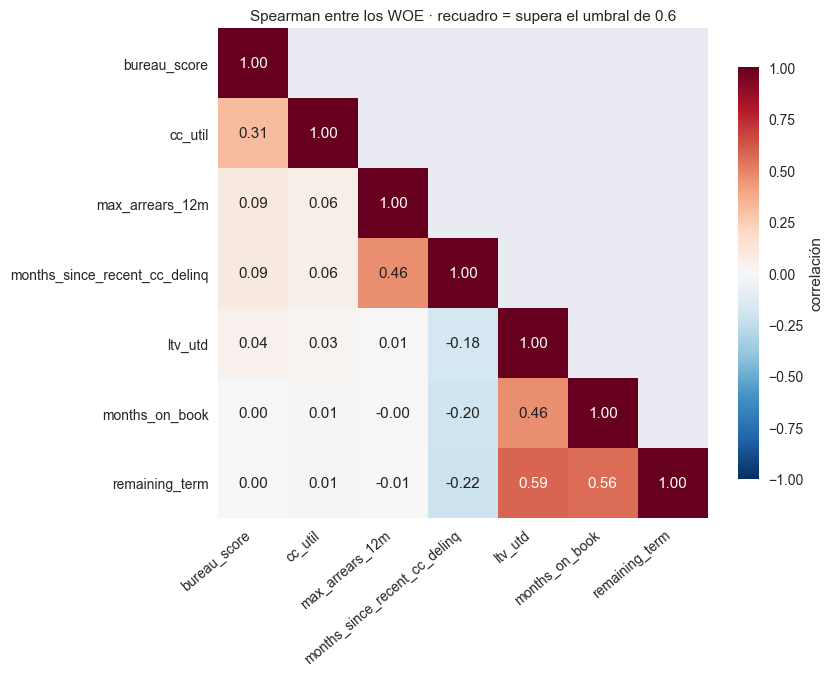

                   variable A                    variable B   rho  |rho|  IV A  IV B sale
                      ltv_utd                remaining_term  0.59   0.59  0.10  0.08    —
               months_on_book                remaining_term  0.56   0.56  0.06  0.08    —
              max_arrears_12m months_since_recent_cc_delinq  0.46   0.46  0.16  0.24    —
                      ltv_utd                months_on_book  0.46   0.46  0.10  0.06    —
                 bureau_score                       cc_util  0.31   0.31  1.17  0.27    —
months_since_recent_cc_delinq                remaining_term -0.22   0.22  0.24  0.08    —
months_since_recent_cc_delinq                months_on_book -0.20   0.20  0.24  0.06    —
months_since_recent_cc_delinq                       ltv_utd -0.18   0.18  0.24  0.10    —
                 bureau_score               max_arrears_12m  0.09   0.09  1.17  0.16    —
                 bureau_score months_since_recent_cc_delinq  0.09   0.09  1.17  0.24    —


In [41]:
UMBRAL = .60
c = train[wc].corr(method='spearman')                                  # matriz entre los WOE vigentes
c.index = c.columns = [v[2:] for v in wc]                              # nombres sin el prefijo w_

fig, ax = plt.subplots(figsize=(8.5, 7))
m = np.triu(np.ones_like(c, dtype=bool), k=1)                          # máscara del triángulo superior
vis = c.mask(m)                                                        # se dibuja solo la mitad inferior
im = ax.imshow(vis, cmap='RdBu_r', vmin=-1, vmax=1)                    # rojo positivo, azul negativo
for i in range(len(c)):
    for j in range(len(c)):
        if not m[i, j]:
            v = c.iloc[i, j]
            alto = (abs(v) > UMBRAL) and i != j                        # marca los pares sobre el umbral
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=11,
                    color='white' if abs(v) > .55 else '#222',
                    fontweight='bold' if alto else 'normal',
                    bbox=dict(fc='none', ec='black', lw=2) if alto else None)
ax.set_xticks(range(len(c))); ax.set_xticklabels(c.columns, rotation=40, ha='right', fontsize=10)
ax.set_yticks(range(len(c))); ax.set_yticklabels(c.index, fontsize=10)
ax.set_title(f'Spearman entre los WOE · recuadro = supera el umbral de {UMBRAL}', fontsize=11)
fig.colorbar(im, ax=ax, shrink=.8, label='correlación')
ax.grid(False); plt.tight_layout(); plt.show()

# el mismo contenido como lista ordenada, que es lo que se usa para decidir
pares = (c.where(m).stack().rename('rho').reset_index()
          .rename(columns={'level_0': 'variable A', 'level_1': 'variable B'}))
pares['|rho|'] = pares.rho.abs()
pares['IV A'] = pares['variable A'].map(ivs).round(3)
pares['IV B'] = pares['variable B'].map(ivs).round(3)
pares['sale'] = np.where(pares['|rho|'] <= UMBRAL, '—',
                         np.where(pares['IV A'] < pares['IV B'], pares['variable A'], pares['variable B']))
print(pares.sort_values('|rho|', ascending=False).head(10).round(2).to_string(index=False))

## Regresión logística y stepwise

**Por qué una logística.** El objetivo es una probabilidad entre 0 y 1. La logística modela el **log-odds** del default como una suma de términos:

$$\ln\left(\frac{PD}{1-PD}\right) = \beta_0 + \beta_1 \cdot WOE_1 + \beta_2 \cdot WOE_2 + \dots$$

Esa suma es lo que después se convierte en puntos: cada variable aporta su parte al puntaje de forma independiente, y eso hace al scorecard **explicable**, tramo por tramo.

**El signo esperado.** El WOE se construyó como buenos sobre malos: un WOE alto es un tramo sano. Como el modelo predice el **default**, a mayor WOE, menor probabilidad: **todos los coeficientes deben ser negativos**.

**Stepwise hacia atrás**, con dos criterios en este orden:

1. **Signo.** Si algún coeficiente sale positivo, se descarta primero. Un signo invertido es síntoma de colinealidad y produce un scorecard absurdo —más mora, mejor puntaje—. Un validador lo rechazaría.
2. **Significancia.** Entre las que tienen el signo correcto, se descarta la de mayor p-valor si supera 5%.

Se repite hasta que todas las variables tengan signo correcto y sean significativas.

Forward juzga a cada variable por lo que vale sola. Backward la juzga por lo que aporta cuando están todas.

In [42]:
# el modelo completo, antes de descartar nada
m_full = sm.Logit(y_tr, sm.add_constant(train[wc])).fit(disp=0)
print('Modelo completo, sin descartar nada:')
print(pd.DataFrame({'coef': m_full.params.round(4), 'p-valor': m_full.pvalues.round(4)}).to_string())

NameError: name 'y_tr' is not defined

In [ ]:
# la misma variable, sola
for v in ['w_max_arrears_12m', 'w_months_since_recent_cc_delinq']:
    m1 = sm.Logit(y_tr, sm.add_constant(train[[v]])).fit(disp=0)
    print(f'{v:34s} sola: coef {m1.params[v]:+.4f}')

w_max_arrears_12m                  sola: coef -0.9999
w_months_since_recent_cc_delinq    sola: coef -1.0000


In [ ]:
def stepwise(d, y, cols, alpha=.05):
    sel = list(cols)                                                      # empieza con todas las variables
    while len(sel) > 1:
        m = sm.Logit(y, sm.add_constant(d[sel])).fit(disp=0)              # logística con intercepto
        coef, p = m.params.drop('const'), m.pvalues.drop('const')         # coeficientes y p-valores, sin el intercepto
        if (coef > 0).any():                                              # criterio 1: algún signo invertido
            drop = coef.idxmax(); print(f'  descarta {drop} (SIGNO invertido: coef {coef[drop]:+.4f})')
        elif p.max() > alpha:                                             # criterio 2: la menos significativa, si no pasa el 5%
            drop = p.idxmax(); print(f'  descarta {drop} (p = {p[drop]:.3f})')
        else:
            return sel, m                                                 # todas cumplen: modelo final
        sel.remove(drop)
    return sel, m

y_tr = train.default_event.values.astype(np.float64)                     # objetivo de entrenamiento
print('stepwise hacia atrás:')
sel, modelo = stepwise(train, y_tr, wc)
b = modelo.params.values                                                  # coeficientes finales, intercepto primero
print(modelo.summary())

stepwise hacia atrás:
  descarta w_max_arrears_12m (SIGNO invertido: coef +0.1902)
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:              1196643
Model:                          Logit   Df Residuals:                  1196636
Method:                           MLE   Df Model:                            6
Date:                Tue, 29 Sep 2026   Pseudo R-squ.:                  0.1518
Time:                        16:47:44   Log-Likelihood:            -1.1420e+05
converged:                       True   LL-Null:                   -1.3464e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                              -3.7075      0.007   -527.713      0.000      -3.7

## Del modelo a los puntos, y de los puntos a la PD

**La escala de puntos** (Ejemplo 2.3.2, pp. 45–46) Se pasa de puntos a pd

**La calibración** es el segundo paso del capítulo, separado del primero. El scorecard **ordena**; la calibración fija el **nivel**: qué PD corresponde a cada puntaje. Se estima con una logística de una sola variable, el puntaje, sobre un período elegido. El período decide la filosofía:

- **PIT** (*point-in-time*): se calibra con los **últimos 12 cierres** del desarrollo. La PD queda anclada a las condiciones recientes.
- **TTC** (*through-the-cycle*): se calibra con **todo** el desarrollo, que contiene un ciclo completo. La PD queda anclada al promedio de largo plazo.

**El punto de quiebre.** Si el período de validación se parece al de calibración, cualquiera de las dos acierta. La prueba exigente es un cambio de ciclo: se calibra una PIT con los cierres de 2006 —lo último observable antes de la crisis— y se aplica a los cierres de 2008, cuyas ventanas caen en la recesión. Compara las tres cifras que imprime la celda.

In [ ]:
for sp in (train, test, oot):
    Xd = np.column_stack([np.ones(len(sp))] + [sp[c].values for c in sel])   # intercepto + WOE seleccionados
    sp['pd_score'] = (1/(1+np.exp(-(Xd@b)))).astype(np.float32)              # PD cruda del scorecard
    sp['logodds'] = np.log(sp.pd_score/(1-sp.pd_score))                      # su log-odds: la escala del modelo

# PIT: logística default ~ log-odds, sobre los ÚLTIMOS 12 cierres del desarrollo
ult = pd.concat([train, test])
ult = ult[ult.report_date > FIN_DEV - pd.DateOffset(months=12)]
bc = sm.Logit(ult.default_event.astype(float), sm.add_constant(ult[['logodds']])).fit(disp=0).params.values

# TTC: la misma logística sobre TODO el desarrollo
_dt = pd.concat([train, test])
bt_ = sm.Logit(_dt.default_event.astype(float), sm.add_constant(_dt[['logodds']])).fit(disp=0).params.values

for sp in (train, test, oot):
    sp['pd_pit'] = 1/(1+np.exp(-(bc[0]+bc[1]*sp.logodds)))                   # PD anclada al último año
    sp['pd_ttc'] = 1/(1+np.exp(-(bt_[0]+bt_[1]*sp.logodds)))                 # PD anclada al ciclo completo

print(f'calibración PIT: intercepto {bc[0]:+.4f}  pendiente {bc[1]:.4f}')
print(f'calibración TTC: intercepto {bt_[0]:+.4f}  pendiente {bt_[1]:.4f}')
print(f'PIT calibrada a los 12 cierres hasta {FIN_DEV:%Y-%m}: PD media OOT {oot.pd_pit.mean()*100:.2f}%')
print(f'TTC calibrada a todo el desarrollo:              PD media OOT {oot.pd_ttc.mean()*100:.2f}%')
print(f'DR observada OOT:                                {oot.default_event.mean()*100:.2f}%')

# PUNTO DE QUIEBRE: PIT calibrada con los cierres de 2007, aplicada a los de 2008
base = pd.concat([train, test])
c07 = base[base.report_date.dt.year == 2007]
bq = sm.Logit(c07.default_event.astype(float), sm.add_constant(c07[['logodds']])).fit(disp=0).params.values
c08 = base[base.report_date.dt.year == 2008]
pit_q = (1/(1+np.exp(-(bq[0]+bq[1]*c08.logodds)))).mean()
print(f'\nPUNTO DE QUIEBRE — cierres de 2008 (ventanas dentro de la crisis):')
print(f'  PIT calibrada con los cierres de 2007 : {pit_q*100:.2f}%')
print(f'  TTC (todo el desarrollo)              : {c08.pd_ttc.mean()*100:.2f}%')
print(f'  DR observada                          : {c08.default_event.mean()*100:.2f}%')
del base, _dt

calibración PIT: intercepto -0.0582  pendiente 1.0088
calibración TTC: intercepto -0.0342  pendiente 0.9890
PIT calibrada a los 12 cierres hasta 2014-12: PD media OOT 2.31%
TTC calibrada a todo el desarrollo:              PD media OOT 2.49%
DR observada OOT:                                2.44%

PUNTO DE QUIEBRE — cierres de 2008 (ventanas dentro de la crisis):
  PIT calibrada con los cierres de 2007 : 2.14%
  TTC (todo el desarrollo)              : 2.24%
  DR observada                          : 4.67%


## Validación: ¿el modelo ordena?

**Gini** = 2 × AUC − 1. Mide qué tan bien separa el modelo a los que defaultean de los que no: 0 es azar, 1 es separación perfecta. Depende solo del **orden**, no del nivel de la PD.

**KS**: la máxima distancia entre las distribuciones acumuladas de buenos y malos. Sobre la curva ROC es `max(TPR − FPR)`.

**La distancia entre los tres Gini es el diagnóstico:**
- Entrenamiento contra prueba: si cae mucho, el modelo **memorizó** las cuentas de entrenamiento.
- Prueba contra fuera de tiempo: si cae mucho, el modelo **no es estable en el tiempo**.

In [ ]:
ginis = {nm: 2*roc_auc_score(d_.default_event, d_.pd_score)-1              # Gini = 2·AUC − 1
         for nm, d_ in [('train', train), ('test (cuentas nuevas)', test), ('out-of-time', oot)]}
fpr, tpr, _ = roc_curve(oot.default_event, oot.pd_score)                    # curva ROC fuera de tiempo
print({k: round(v, 3) for k, v in ginis.items()}, f'| KS oot {np.max(tpr-fpr):.3f}')

{'train': 0.622, 'test (cuentas nuevas)': 0.605, 'out-of-time': 0.62} | KS oot 0.466


## Estabilidad de población (PSI)

Antes de interpretar un cambio en el desempeño hay que preguntarse si **la población cambió**. El PSI compara la distribución de una variable entre dos muestras:

$$PSI = \sum_{deciles} (\%_{nueva} - \%_{base}) \times \ln\left(\frac{\%_{nueva}}{\%_{base}}\right)$$

Los deciles se fijan en la muestra base y se aplican a la otra. Criterio de industria: **menos de 0.10 estable, 0.10 a 0.25 vigilar, más de 0.25 inestable**.

Dos comparaciones:
- **Entrenamiento contra fuera de tiempo**: ¿la población de validación se parece a la de desarrollo?
- **Auge (2006) contra crisis (2009)**: ¿cuánto se desplaza la población cuando cambia el ciclo? Aquí es donde se ve qué variables arrastra la economía.

In [ ]:
def psi(v, base, comp, q=10):
    cortes = np.nanquantile(base[v], np.linspace(0, 1, q+1))[1:-1]        # deciles de la muestra BASE
    a = np.histogram(base[v].dropna(), bins=[-np.inf, *cortes, np.inf])[0] / base[v].notna().sum()   # % base por decil
    bb = np.histogram(comp[v].dropna(), bins=[-np.inf, *cortes, np.inf])[0] / comp[v].notna().sum()  # % nueva por decil
    # np.maximum evita el logaritmo de cero en deciles vacíos
    return float(np.sum((bb-a)*np.log(np.maximum(bb, 1e-6)/np.maximum(a, 1e-6))))

tab = pd.DataFrame({'PSI': {v: round(psi(v, train, oot), 3) for v in
                            ['bureau_score', 'cc_util', 'ltv_utd', 'months_on_book',
                             'months_since_recent_cc_delinq', 'pd_score']}})
tab['veredicto'] = pd.cut(tab.PSI, [-np.inf, .10, .25, np.inf], labels=['estable', 'vigilar', 'INESTABLE'])
print('PSI entrenamiento -> fuera de tiempo:')
print(tab.sort_values('PSI', ascending=False).to_string())

_b = pd.concat([train, test])
auge, crisis = _b[_b.report_date.dt.year == 2006], _b[_b.report_date.dt.year == 2009]
tab_ac = pd.DataFrame({'PSI auge->crisis': {v: round(psi(v, auge, crisis), 3)
                        for v in ['bureau_score', 'cc_util', 'ltv_utd', 'months_since_recent_cc_delinq', 'pd_score']}})
tab_ac['media 2006'] = [round(auge[v].mean(), 2) for v in tab_ac.index]
tab_ac['media 2009'] = [round(crisis[v].mean(), 2) for v in tab_ac.index]
print('\nPSI entre el auge (2006) y la crisis (2009):')
print(tab_ac.sort_values('PSI auge->crisis', ascending=False).to_string())
del _b


PSI entrenamiento -> fuera de tiempo:
                                 PSI veredicto
months_on_book                 0.037   estable
ltv_utd                        0.031   estable
months_since_recent_cc_delinq  0.018   estable
pd_score                       0.002   estable
cc_util                        0.000   estable
bureau_score                   0.000   estable

PSI entre el auge (2006) y la crisis (2009):
                               PSI auge->crisis  media 2006  media 2009
ltv_utd                                   0.329    0.390000    0.530000
pd_score                                  0.035    0.020000    0.030000
months_since_recent_cc_delinq             0.025   68.379997   71.650002
bureau_score                              0.006  524.730000  519.790000
cc_util                                   0.000    0.380000    0.380000


## Machine Learning como contraste

Un bosque aleatorio sobre las **variables originales**, sin WOE ni poda, para medir cuánto poder deja sobre la mesa el scorecard. El bosque captura relaciones no lineales e interacciones que un scorecard aditivo no modela.

Con millones de filas el bosque se entrena sobre una **muestra de cuentas** —6,000, con todas sus filas—, nunca de filas sueltas: una cuenta quedaría a medias. `min_samples_leaf=200` evita hojas con pocas observaciones, que memorizarían ruido. `fillna(-999)` le da a los faltantes un valor que el árbol puede separar.

Si el bosque gana, la pregunta es si esa diferencia justifica perder la interpretabilidad. En banca regulada un scorecard que se explica a un supervisor y se audita tramo por tramo suele ser la decisión correcta, aunque ceda algo de Gini.

In [ ]:
rng = np.random.default_rng(2122)                                          # generador con semilla fija
feats = ['bureau_score', 'annual_income', 'emp_length', 'cc_util', 'num_ccj', 'max_arrears_12m',
         'arrears_months', 'ltv_utd', 'dti', 'bureau_searches_6m', 'time_at_address_years',
         'months_since_recent_cc_delinq', 'months_on_book', 'remaining_term']
sub = train[train.id.isin(set(rng.choice(train.id.unique(), 6000, replace=False)))]   # 6,000 cuentas completas
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=200, n_jobs=-1, random_state=2122)
rf.fit(sub[feats].fillna(-999), sub.default_event)
g_rf = 2*roc_auc_score(oot.default_event, rf.predict_proba(oot[feats].fillna(-999))[:, 1])-1   # Gini OOT del bosque
print(f"Gini OOT - GLM {ginis['out-of-time']:.3f} | Random Forest {g_rf:.3f} "
      f"(entrenado con {len(sub):,} filas de 6,000 cuentas)")

Gini OOT - GLM 0.620 | Random Forest 0.659 (entrenado con 461,880 filas de 6,000 cuentas)


## Backtest: PD del modelo contra lo que ocurrió

El gráfico que cierra el capítulo. Para cada cierre de mes compara:

- **Línea roja**: la DR que efectivamente ocurrió en los 12 meses siguientes. Cada punto es el **futuro** de su fecha.
- **Línea azul**: la PD promedio que el modelo, calibrado TTC, le asignó a esa misma cartera en esa fecha.

La distancia vertical entre ambas es el error de predicción de esa cartera. La banda gris es el embargo y la línea punteada el inicio de la validación. Las líneas se **cortan** en el embargo a propósito: `reindex` completa esos meses con vacíos para que matplotlib no una con una recta puntos que no existen.

**Cómo leerlo:**
1. **Nivel.** Una PD TTC está anclada al promedio del ciclo: se espera que sobreestime en los años buenos y subestime en los malos.
2. **Movimiento.** Si las variables del scorecard se deterioran en la crisis, la línea azul sube en los años malos. Mira **cuánto** sube frente a la roja.
3. **Momento.** La celda busca el pico de cada curva dentro de la crisis y calcula el rezago en meses. Si la PD sube después que la DR, el modelo reacciona en vez de anticipar.
4. **Fuera de tiempo.** Si esos años se parecen al promedio del desarrollo, las curvas andarán cerca aunque el modelo no anticipe nada.

Lo que el backtest mide es el **nivel**, no el orden: el orden ya lo midió el Gini. Una PD a 12 meses que no incorpora cómo va a estar la economía es un **insumo**, no la PD del ECL: le falta la información prospectiva, que es el capítulo 3.

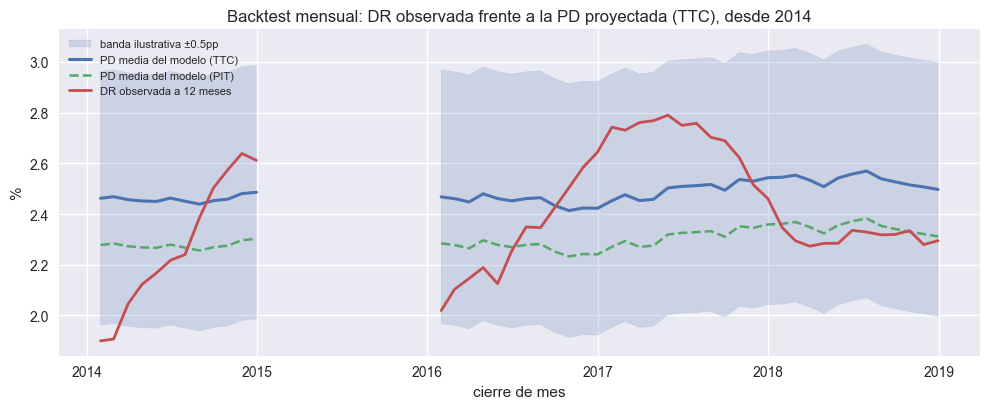

In [ ]:
z = 0.5  

vis = bt[bt.index >= '2014-01-01']

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.fill_between(vis.index, vis.ttc * 100 - z, vis.ttc * 100 + z,
                color='#4c72b0', alpha=.20, label=f'banda ilustrativa ±{z}pp')
ax.plot(vis.index, vis.ttc * 100, lw=2.2, c='#4c72b0', label='PD media del modelo (TTC)')
ax.plot(vis.index, vis.pit * 100, lw=1.8, c='#55a868', ls='--', label='PD media del modelo (PIT)')
ax.plot(vis.index, vis.obs * 100, lw=2.0, c='#c44e52', label='DR observada a 12 meses')
ax.set_ylabel('%'); ax.set_xlabel('cierre de mes'); ax.legend(loc='upper left', fontsize=8)
ax.set_title('Backtest mensual: DR observada frente a la PD proyectada (TTC), desde 2014')
plt.tight_layout(); plt.savefig('figs_m/backtest_mensual_ic_2014.png', dpi=110); plt.show()


In [ ]:
# ======== ENTREGA AL CAPÍTULO 3: la PD a 12 meses de cada cuenta en cada cierre ========


emb = df[(df.report_date > FIN_DEV) & (df.report_date < INICIO_OOT)].copy()      # los 12 cierres de 2015
for c in sel:                                                                     # WOE con los cortes de train
    emb[c] = apply_woe(emb[c[2:]], tabs[c[2:]], bins[c[2:]])
Xd = np.column_stack([np.ones(len(emb))] + [emb[c].values for c in sel])
emb['pd_score'] = 1 / (1 + np.exp(-(Xd @ b)))                                    # PD cruda del modelo
emb['logodds'] = np.log(emb.pd_score / (1 - emb.pd_score))
emb['pd_pit'] = 1 / (1 + np.exp(-(bc[0] + bc[1] * emb.logodds)))                # misma calibración PIT

entrega = pd.concat([sp[['id', 'report_date', 'pd_pit']] for sp in (train, test, emb, oot)])
entrega = entrega.rename(columns={'pd_pit': 'pd_12m'}).sort_values(['id', 'report_date']).reset_index(drop=True)

# controles: una fila por cuenta y cierre, las mismas filas que la base, sin vacíos
assert len(entrega) == len(df), 'no cubre todas las filas de la base'
assert not entrega.duplicated(['id', 'report_date']).any(), 'hay cuentas repetidas en un cierre'
assert entrega.pd_12m.notna().all(), 'hay PD vacías'
entrega.to_parquet('pd_cap2_mensual.parquet', index=False)

print('modelo  :', [c[2:] for c in sel])
print(f'calibración PIT: intercepto {bc[0]:+.4f} | pendiente {bc[1]:.4f}')
print(f'entregado: pd_cap2_mensual.parquet · {len(entrega):,} filas · {entrega.id.nunique():,} cuentas · '
      f'{entrega.report_date.nunique()} cierres ({entrega.report_date.min():%Y-%m} a {entrega.report_date.max():%Y-%m})')
por_bloque = {'train': train, 'test': test, 'embargo 2015': emb, 'fuera de tiempo': oot}
for k, sp in por_bloque.items():
    print(f'  {k:16s} {len(sp):>9,} filas | PD media {sp.pd_pit.mean()*100:.2f}% | DR {sp.default_event.mean()*100:.2f}%')

modelo  : ['bureau_score', 'cc_util', 'months_since_recent_cc_delinq', 'ltv_utd', 'months_on_book', 'remaining_term']
calibración PIT: intercepto -0.0582 | pendiente 1.0088
entregado: pd_cap2_mensual.parquet · 2,302,232 filas · 26,100 cuentas · 192 cierres (2003-01 a 2018-12)
  train            1,196,643 filas | PD media 2.20% | DR 2.38%
  test               515,193 filas | PD media 2.19% | DR 2.37%
  embargo 2015       147,285 filas | PD media 2.29% | DR 2.36%
  fuera de tiempo    443,111 filas | PD media 2.31% | DR 2.44%
